# 06 · Evaluation of the Best Model
## Kenyan Sign Language (KSL) Recognition with Deep Learning

| | |
|---|---|
| **Course** | DSA 4050-XA: Deep Learning, USIU-Africa (Fall 2026) |
| **Student** | Selmah Tzindori (669602) |
| **Notebook** | `06_evaluation.ipynb` |
| **Term paper part** | (c) model evaluation, plus material for (d) the dashboard |

### Objective
Look beyond a single accuracy number for the best model, **EfficientNetB0 (extended fine-tuning)**, and compare it with the best classic model, **HOG + SVM**:
1. Headline metrics with **95% confidence intervals**
2. **Confusion matrices** and **per-sign** results: which signs did deep learning fix?
3. **Confidence**: how sure is the model, and can low confidence flag likely mistakes?
4. **Misclassified examples**
5. **Grad-CAM**: *where* in the image the model looks
6. **Robustness**: accuracy under blur, darkness, rotation and noise, as a stand-in for new real-world conditions

No training happens here; it takes about 10 minutes.

### Inputs
- `models/dl_best.keras`, `models/classic_best.pkl`
- `data/processed/ksl_224.zip`, `catalogue_split.csv`

### Outputs
- `06_*.png` figures and `06_*.csv` tables in `outputs/`
- Key numbers in `results.json` (confidence intervals, threshold, robustness)

## 0 · Setup

In [1]:
# =============================================================================
# STANDARD SETUP CELL
# =============================================================================
from google.colab import drive
drive.mount("/content/drive")

import sys
sys.path.insert(0, "/content/drive/MyDrive/DSA4050/ksl-recognition/src")

import importlib
import ksl_utils as ku
importlib.reload(ku)
ku.set_seed()

NOTEBOOK = "06_evaluation"
PATHS = ku.PATHS
print("Project root:", ku.PROJECT_ROOT)

Mounted at /content/drive
Random seed set to 42
Project root: /content/drive/MyDrive/DSA4050/ksl-recognition


In [2]:
# Libraries used in this notebook
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
import keras
from PIL import Image, ImageFilter, ImageEnhance
from tqdm.auto import tqdm
from skimage.feature import hog
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
DL_COLOUR, CLASSIC_COLOUR = "#2E7D6B", "#B0B0B0"

In [3]:
# Data, class names and the two models being compared
PROC_DIR = Path(ku.restore_processed_data())
cat = ku.load_split_catalogue()
CLASS_NAMES = ku.load_class_names()
N = len(CLASS_NAMES)

test = cat[cat["split"] == "test"].reset_index(drop=True)
y_true = test["label_idx"].to_numpy()

DL_NAME = ku.load_results()["best_dl_model"]["value"]
dl_model = keras.models.load_model(ku.model_path("dl_best"))
classic = joblib.load(ku.model_path("classic_best", "pkl"))
CLASSIC_NAME = ku.load_results()["best_classic_model"]["value"]
print(f"Deep model   : {DL_NAME} ({dl_model.count_params() / 1e6:.2f}M weights)")
print(f"Classic model: {CLASSIC_NAME}")
print(f"Test images  : {len(test)}")

Processed data restored to /content/ksl_224 in 4s
Deep model   : efficientnetb0_ft2 (4.06M weights)
Classic model: hog+svm_rbf
Test images  : 941


### 0.1 · Prediction helpers
The test images are loaded once as a 941 × 224 × 224 × 3 array. Two small functions turn any (possibly altered) batch of images into predictions from each model, so the same code serves the main evaluation and the robustness tests in Section 6. The classic model receives exactly the inputs it was trained on (64×64 greyscale → HOG).

In [4]:
def load_rgb(file: str) -> np.ndarray:
    with Image.open(PROC_DIR / file) as img:
        return np.asarray(img.convert("RGB"), dtype=np.uint8)

X_test = np.stack([load_rgb(f) for f in tqdm(test["proc_file"], desc="Loading test images")])


def dl_predict(images: np.ndarray) -> np.ndarray:
    """Class probabilities from the deep model (inputs: uint8 RGB 224x224)."""
    return dl_model.predict(images.astype("float32"), batch_size=64, verbose=0)


def classic_features(images: np.ndarray) -> np.ndarray:
    """Re-create the classic model's input features from RGB images."""
    feats = []
    for im in images:
        size = 64 if classic["features"] == "hog" else 32
        grey = np.asarray(Image.fromarray(im).convert("L").resize((size, size), Image.Resampling.BILINEAR),
                          dtype=np.float32) / 255.0
        feats.append(hog(grey, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2),
                         block_norm="L2-Hys", feature_vector=True) if classic["features"] == "hog"
                     else grey.ravel())
    return np.stack(feats).astype(np.float32)


def classic_predict(images: np.ndarray) -> np.ndarray:
    return classic["pipeline"].predict(classic_features(images))


start = time.time()
dl_probs = dl_predict(X_test)
dl_pred = dl_probs.argmax(axis=1)
classic_pred = classic_predict(X_test)
print(f"Predictions done in {time.time() - start:.0f}s")

Loading test images:   0%|          | 0/941 [00:00<?, ?it/s]

Predictions done in 17s


## 1 · Headline metrics with 95% confidence intervals
A single test score depends on which 941 images ended up in the test set. **Bootstrapping** resamples the test set 2,000 times (with replacement) and recomputes the metric each time; the middle 95% of those values gives a **95% confidence interval**. If the intervals of two models do not overlap, the difference is very unlikely to be luck.

**Top-2 accuracy** counts a prediction as correct if the true sign is among the model's **two** most likely signs, which is useful for a dashboard that shows the top suggestions.

In [5]:
def bootstrap_ci(y, pred, metric, n_boot=2000, seed=ku.SEED):
    """95% bootstrap confidence interval for a metric(y, pred)."""
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(y), size=(n_boot, len(y)))
    vals = np.array([metric(y[i], pred[i]) for i in idx])
    return np.percentile(vals, [2.5, 97.5])

macro_f1 = lambda a, b: f1_score(a, b, average="macro")
top2 = np.mean([t in p for t, p in zip(y_true, np.argsort(dl_probs, axis=1)[:, -2:])])

rows = []
for name, pred in [(f"Deep learning: {DL_NAME}", dl_pred), (f"Classic: {CLASSIC_NAME}", classic_pred)]:
    acc_ci = bootstrap_ci(y_true, pred, accuracy_score)
    f1_ci = bootstrap_ci(y_true, pred, macro_f1)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_true, pred),
                 "accuracy_95ci": f"{acc_ci[0]:.3f}–{acc_ci[1]:.3f}",
                 "macro_f1": macro_f1(y_true, pred),
                 "macro_f1_95ci": f"{f1_ci[0]:.3f}–{f1_ci[1]:.3f}"})
headline = pd.DataFrame(rows)
headline["top2_accuracy"] = [top2, np.nan]
ku.save_table(headline.round(4), "06_headline_metrics", NOTEBOOK,
              caption="Test accuracy and macro-F1 with 95% bootstrap confidence intervals.")

ku.log_result("dl_test_accuracy_95ci", rows[0]["accuracy_95ci"], NOTEBOOK)
ku.log_result("classic_test_accuracy_95ci", rows[1]["accuracy_95ci"], NOTEBOOK)
ku.log_result("dl_top2_accuracy", round(float(top2), 4), NOTEBOOK)
headline.round(3)

Table saved  -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/tables/06_headline_metrics.csv
Result logged: dl_test_accuracy_95ci = 0.827–0.872
Result logged: classic_test_accuracy_95ci = 0.571–0.632
Result logged: dl_top2_accuracy = 0.9469


,model,accuracy,accuracy_95ci,macro_f1,macro_f1_95ci,top2_accuracy
0,Deep learning: efficientnetb0_ft2,0.85,0.827–0.872,0.850,0.826–0.872,0.947
1,Classic: hog+svm_rbf,0.60,0.571–0.632,0.603,0.572–0.633,NaN


**Interpretation:** the deep model scores **85.0% accuracy (95% CI 82.7–87.2%)** and the classic model **60.0% (57.1–63.2%)**. The intervals are far apart, so the **25-point gap is not due to chance** in the test split. Macro-F1 tells the same story (0.850 vs 0.603). **Top-2 accuracy is 94.7%**: when the model is wrong, the correct sign is usually its second choice, which a dashboard can show as an alternative.

*Note:* notebook 05 reported 86.0% for the same model. The 1-point difference (9 of 941 images) comes from decoding the JPEG files with a different library (TensorFlow there, Pillow here, as the dashboard will use). Both values lie inside the confidence interval; the report quotes **85–86%**.

## 2 · Confusion matrices: classic vs deep learning
Rows are the true sign, columns the predicted sign, and each row sums to 1. A strong model has a bright diagonal and pale off-diagonal cells.

Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/06_confusion_classic_vs_dl.png


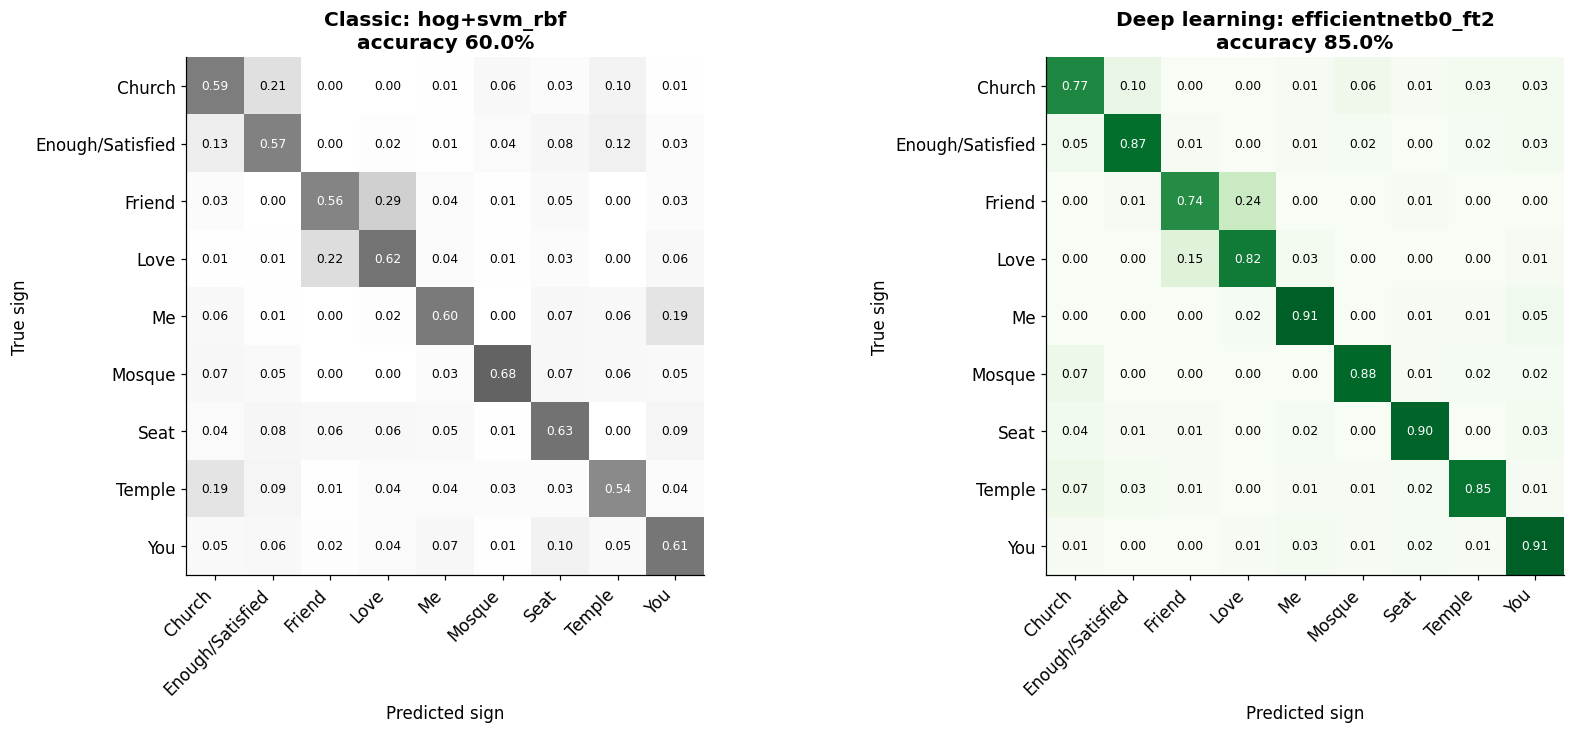

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.8))
for ax, (title, pred, cmap) in zip(axes, [(f"Classic: {CLASSIC_NAME}", classic_pred, "Greys"),
                                         (f"Deep learning: {DL_NAME}", dl_pred, "Greens")]):
    cm = confusion_matrix(y_true, pred, normalize="true")
    ax.imshow(cm, cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(range(N), CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticks(range(N), CLASS_NAMES)
    for i in range(N):
        for j in range(N):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xlabel("Predicted sign")
    ax.set_ylabel("True sign")
    ax.set_title(f"{title}\naccuracy {accuracy_score(y_true, pred):.1%}")
fig.tight_layout()
ku.save_figure(fig, "06_confusion_classic_vs_dl", NOTEBOOK,
               caption="Normalised confusion matrices of the best classic and best deep-learning models.")
plt.show()

In [7]:
# The deep model's most common remaining confusions
cm_dl = pd.DataFrame(confusion_matrix(y_true, dl_pred, normalize="true"), index=CLASS_NAMES, columns=CLASS_NAMES)
cm_cl = pd.DataFrame(confusion_matrix(y_true, classic_pred, normalize="true"), index=CLASS_NAMES, columns=CLASS_NAMES)
pairs = cm_dl.stack().rename("deep_learning").to_frame()
pairs["classic"] = cm_cl.stack()
pairs = pairs[[a != b for a, b in pairs.index]].sort_values("deep_learning", ascending=False).head(6)
pairs.index = [f"{a} → {b}" for a, b in pairs.index]
ku.save_table(pairs.round(3).reset_index(names="true → predicted"), "06_top_confusions", NOTEBOOK,
              caption="Most frequent confusions of the deep model, with the classic model's rate for comparison.")
pairs.round(3)

Table saved  -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/tables/06_top_confusions.csv


,deep_learning,classic
Friend → Love,0.238,0.286
Love → Friend,0.146,0.223
Church → Enough/Satisfied,0.096,0.212
Mosque → Church,0.067,0.067
Temple → Church,0.067,0.190
Church → Mosque,0.058,0.058


**Interpretation:** the deep model's diagonal is much brighter (0.74–0.91 per sign, vs 0.54–0.68 for the classic model). The remaining errors are the **same look-alike pairs found in the EDA**, but less frequent:
- *Friend → Love*: 23.8% (classic 28.6%) and *Love → Friend*: 14.6% (classic 22.3%). Crossed arms with open hands vs fists remains the hardest distinction.
- *Church → Enough/Satisfied*: 9.6% (classic 21.2%) and *Temple → Church*: 6.7% (classic 19.0%). These were largely fixed.
- *Mosque ↔ Church* (≈6%) did not improve: both involve one hand resting on or over the other.

## 3 · Per-sign comparison
F1-score per sign for both models; the gap shows where learned features helped most.

Table saved  -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/tables/06_per_sign.csv
Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/06_per_sign_f1.png


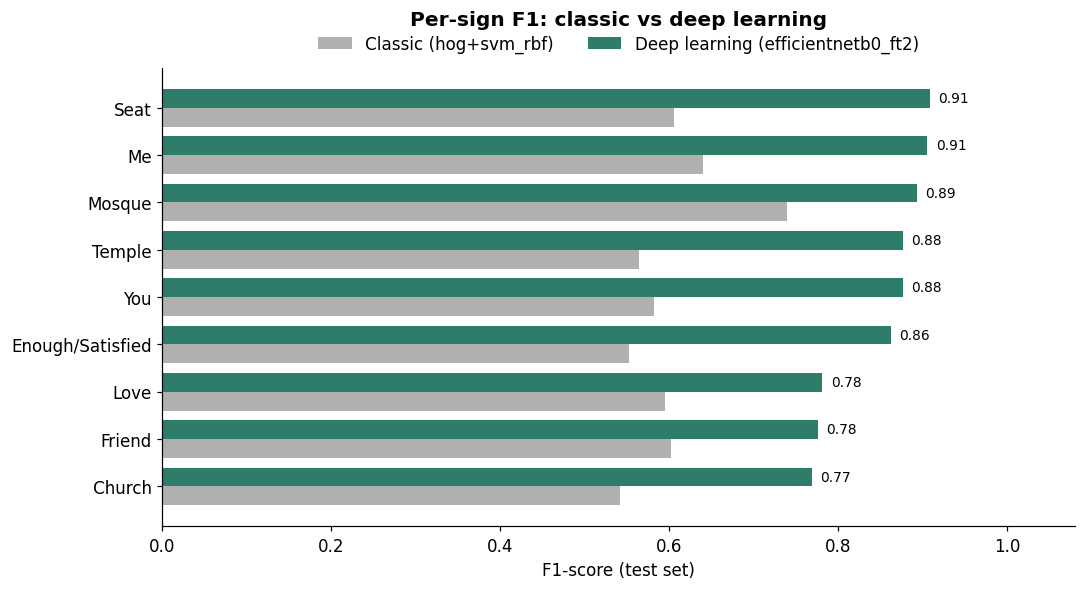

,precision_dl,recall_dl,f1_dl,f1_classic,f1_gain
Church,0.769,0.769,0.769,0.542,0.227
Enough/Satisfied,0.858,0.867,0.863,0.553,0.310
Friend,0.812,0.743,0.776,0.602,0.174
Love,0.750,0.816,0.781,0.595,0.186
Me,0.897,0.914,0.906,0.640,0.266
Mosque,0.902,0.885,0.893,0.740,0.154
Seat,0.922,0.895,0.908,0.606,0.303
Temple,0.908,0.848,0.877,0.564,0.312
You,0.842,0.914,0.877,0.582,0.295


In [8]:
rep_dl = pd.DataFrame(classification_report(y_true, dl_pred, target_names=CLASS_NAMES, output_dict=True)).T
rep_cl = pd.DataFrame(classification_report(y_true, classic_pred, target_names=CLASS_NAMES, output_dict=True)).T
per_sign = pd.DataFrame({"precision_dl": rep_dl.loc[CLASS_NAMES, "precision"],
                         "recall_dl": rep_dl.loc[CLASS_NAMES, "recall"],
                         "f1_dl": rep_dl.loc[CLASS_NAMES, "f1-score"],
                         "f1_classic": rep_cl.loc[CLASS_NAMES, "f1-score"]})
per_sign["f1_gain"] = per_sign["f1_dl"] - per_sign["f1_classic"]
ku.save_table(per_sign.round(3).reset_index(names="sign"), "06_per_sign", NOTEBOOK,
              caption="Per-sign precision, recall and F1 of the deep model, with the classic model's F1.")

order = per_sign.sort_values("f1_dl").index
fig, ax = plt.subplots(figsize=(10, 5.5))
yy = np.arange(len(order))
ax.barh(yy - 0.2, per_sign.loc[order, "f1_classic"], height=0.4, color=CLASSIC_COLOUR, label=f"Classic ({CLASSIC_NAME})")
ax.barh(yy + 0.2, per_sign.loc[order, "f1_dl"], height=0.4, color=DL_COLOUR, label=f"Deep learning ({DL_NAME})")
for y_, v in zip(yy, per_sign.loc[order, "f1_dl"]):
    ax.text(v + 0.01, y_ + 0.2, f"{v:.2f}", va="center", fontsize=9)
ax.set_yticks(yy, order)
ax.set_xlim(0, 1.08)
ax.set_xlabel("F1-score (test set)")
ax.set_title("Per-sign F1: classic vs deep learning", pad=28)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
fig.tight_layout()
ku.save_figure(fig, "06_per_sign_f1", NOTEBOOK, caption="Per-sign F1-score of the classic and deep-learning models.")
plt.show()
per_sign.round(3)

**Interpretation:** deep learning improves **every sign**, by 0.15–0.31 F1. The largest gains are for **Temple (+0.31), Enough/Satisfied (+0.31), Seat (+0.30) and You (+0.30)**, signs whose hand shapes (finger positions, pointing, interlocking) HOG could not capture. The easiest signs are now **Seat (F1 0.91), Me (0.91) and Mosque (0.89)**; the hardest remain **Church (0.77), Friend (0.78) and Love (0.78)**, the members of the look-alike pairs.

## 4 · How confident is the model?
The model outputs a probability for every sign; its **confidence** is the highest probability. A useful model should be **more confident when it is right** than when it is wrong. If so, the dashboard can show *"not sure, please try again"* below a confidence threshold instead of a wrong answer.

Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/06_confidence.png


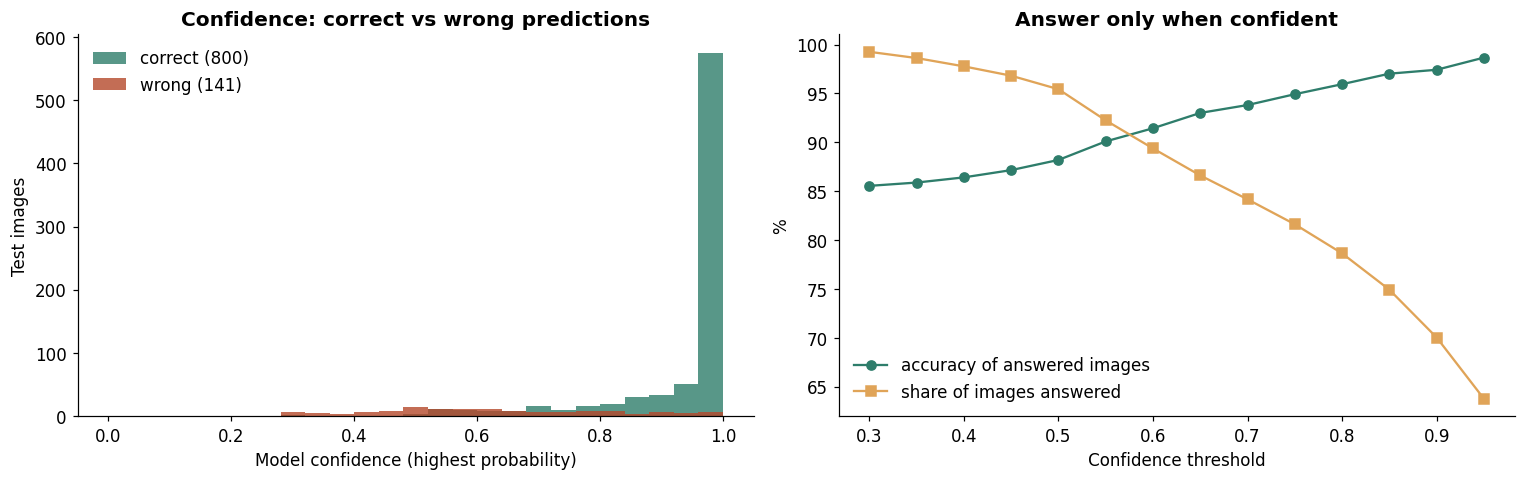

Result logged: dashboard_conf_threshold = 0.8
Result logged: acc_above_threshold = 0.9595
Result logged: coverage_above_threshold = 0.7864
Median confidence: correct 0.99 | wrong 0.62
Threshold 0.80: answers 78.6% of images with 95.9% accuracy


In [9]:
conf = dl_probs.max(axis=1)
correct = dl_pred == y_true

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bins = np.linspace(0, 1, 26)
axes[0].hist(conf[correct], bins=bins, alpha=0.8, color=DL_COLOUR, label=f"correct ({correct.sum()})")
axes[0].hist(conf[~correct], bins=bins, alpha=0.8, color="#B5482B", label=f"wrong ({(~correct).sum()})")
axes[0].set_xlabel("Model confidence (highest probability)")
axes[0].set_ylabel("Test images")
axes[0].set_title("Confidence: correct vs wrong predictions")
axes[0].legend(frameon=False)

# Accuracy on the predictions the model is willing to make, for each threshold
thresholds = np.arange(0.30, 0.96, 0.05)
acc_kept = [correct[conf >= t].mean() for t in thresholds]
coverage = [(conf >= t).mean() for t in thresholds]
axes[1].plot(thresholds, np.array(acc_kept) * 100, marker="o", color=DL_COLOUR, label="accuracy of answered images")
axes[1].plot(thresholds, np.array(coverage) * 100, marker="s", color="#E0A458", label="share of images answered")
axes[1].set_xlabel("Confidence threshold")
axes[1].set_ylabel("%")
axes[1].set_title("Answer only when confident")
axes[1].legend(frameon=False)
fig.tight_layout()
ku.save_figure(fig, "06_confidence", NOTEBOOK, caption="Confidence of correct and wrong predictions, and the accuracy/coverage trade-off of a confidence threshold.")
plt.show()

# Smallest threshold that gives at least 95% accuracy on answered images
ok = [t for t, a in zip(thresholds, acc_kept) if a >= 0.95]
THRESHOLD = float(round(ok[0], 2)) if ok else 0.7
cov = float((conf >= THRESHOLD).mean())
ku.log_result("dashboard_conf_threshold", THRESHOLD, NOTEBOOK)
ku.log_result("acc_above_threshold", round(float(correct[conf >= THRESHOLD].mean()), 4), NOTEBOOK)
ku.log_result("coverage_above_threshold", round(cov, 4), NOTEBOOK)
print(f"Median confidence: correct {np.median(conf[correct]):.2f} | wrong {np.median(conf[~correct]):.2f}")
print(f"Threshold {THRESHOLD:.2f}: answers {cov:.1%} of images with "
      f"{correct[conf >= THRESHOLD].mean():.1%} accuracy")

**Interpretation:** confidence separates right from wrong answers well: the median confidence is **0.99 for correct** predictions but **0.62 for wrong** ones. With a **threshold of 0.80**, the model answers **78.6% of images with 95.9% accuracy**, and the remaining 21% get a "not sure, please try again" message. The dashboard uses this threshold, trading some coverage for much more trustworthy answers.

## 5 · Misclassified examples
The 16 mistakes the model was **most confident** about. These show whether errors come from genuinely ambiguous images (blur, hands cut off by the crop, look-alike signs) or from real model weaknesses.

Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/06_misclassified.png


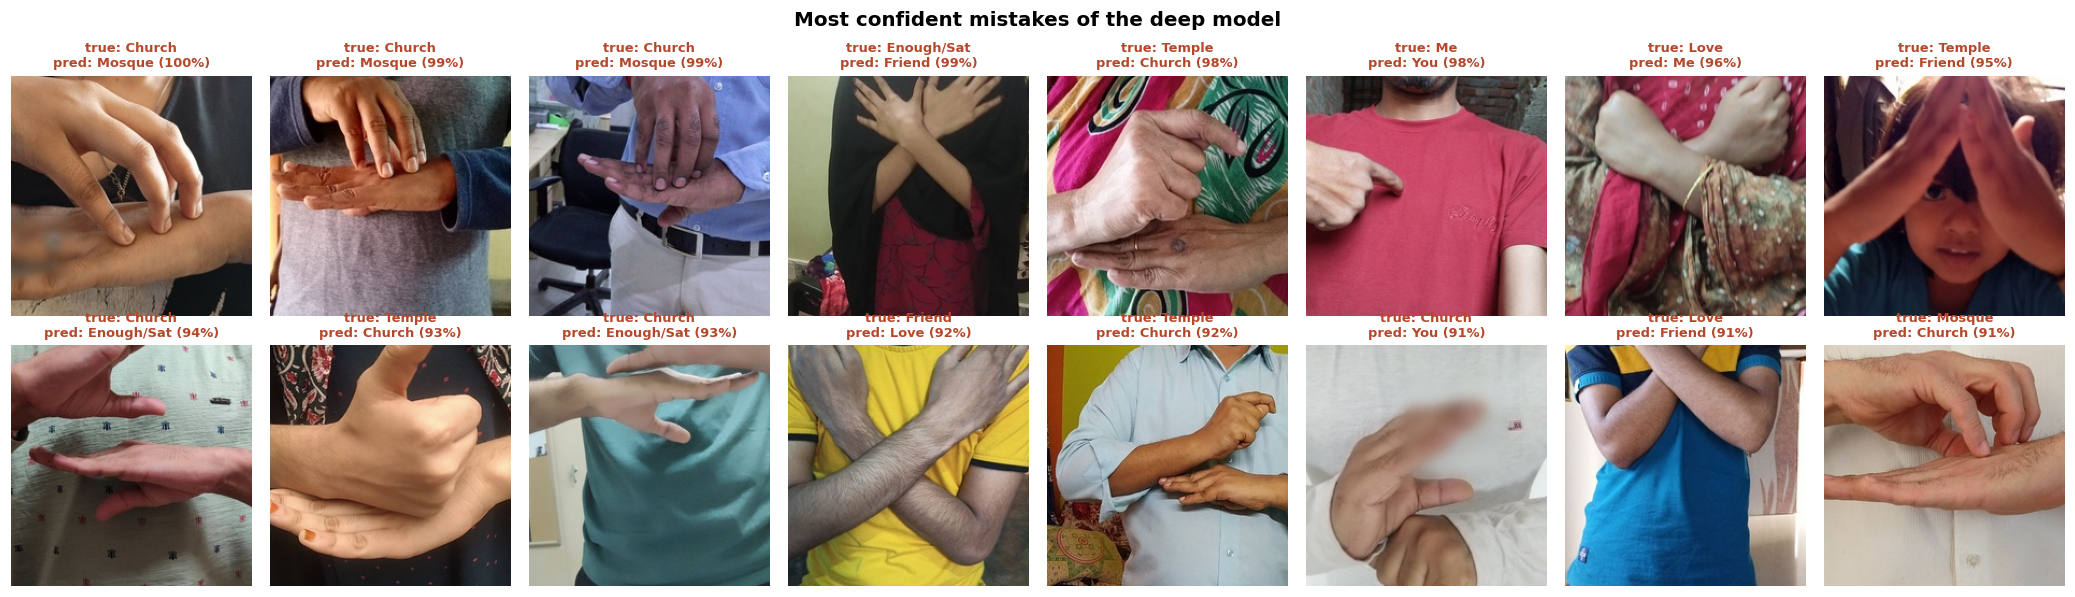

In [10]:
wrong = np.where(~correct)[0]
worst = wrong[np.argsort(-conf[wrong])][:16]

fig, axes = plt.subplots(2, 8, figsize=(19, 5.6))
for ax, i in zip(axes.flat, worst):
    ax.imshow(X_test[i])
    ax.set_title(f"true: {CLASS_NAMES[y_true[i]][:10]}\npred: {CLASS_NAMES[dl_pred[i]][:10]} ({conf[i]:.0%})",
                 fontsize=8.5, color="#B5482B")
    ax.axis("off")
for ax in list(axes.flat)[len(worst):]:
    ax.axis("off")
fig.suptitle("Most confident mistakes of the deep model", fontsize=13, fontweight="bold")
fig.tight_layout()
ku.save_figure(fig, "06_misclassified", NOTEBOOK, caption="The 16 most confident misclassifications of the deep model.")
plt.show()

**Interpretation:** two kinds of mistakes appear:
1. **Probable labelling errors in the dataset.** Several of the most confident "mistakes" look like the *predicted* sign rather than the labelled one: e.g. images labelled *Church* where one hand's fingers tap the other wrist (the *Mosque* sign), and an *Enough/Satisfied* image showing arms crossed with open hands (*Friend*). In those cases the model may be right and the label wrong, so the true accuracy may be slightly higher than reported. Without access to Deaf signers this cannot be confirmed; it is noted as a limitation.
2. **Genuine look-alikes and hard images:** crossed arms (*Friend*/*Love*), flat stacked hands (*Church*/*Enough*/*Temple*), a pointing finger near the chest (*Me*/*You*), and images with blurred or partly cropped hands.

## 6 · Grad-CAM: where does the model look?
**Grad-CAM** (Gradient-weighted Class Activation Mapping) highlights the image regions that pushed the model towards its prediction. It takes the last convolutional feature maps, weights each by how strongly it influences the predicted class (its gradient), and overlays the result as a heatmap: **red = most important**.

If the model has learned the right thing, the heat should sit on the **hands and arms**, not on the background, face or clothing. This is a key check that 86% accuracy comes from the sign itself.

In [11]:
def split_model(model):
    """Return (layers before the pretrained base, the base, layers after it)."""
    nested = [l for l in model.layers if isinstance(l, keras.Model) and len(l.layers) > 20]
    if not nested:
        return None, None, None
    base = nested[0]
    idx = model.layers.index(base)
    pre = [l for l in model.layers[1:idx] if l.name != "augmentation"]   # e.g. rescaling; skip augmentation
    post = [l for l in model.layers[idx + 1:]]                            # pooling, dropout, dense
    return pre, base, post


def grad_cam(model, image: np.ndarray, class_idx=None):
    """Grad-CAM heatmap (224x224, values 0-1) and the predicted class for one uint8 image."""
    x = tf.convert_to_tensor(image[None].astype("float32"))
    pre, base, post = split_model(model)
    with tf.GradientTape() as tape:
        if base is not None:                                  # transfer model: base output = last conv maps
            for l in pre:
                x = l(x)
            conv = base(x, training=False)
            tape.watch(conv)
            out = conv
            for l in post:
                out = l(out, training=False)
        else:                                                 # scratch CNN: use its last Conv2D layer
            last_conv = [l for l in model.layers if isinstance(l, keras.layers.Conv2D)][-1]
            sub = keras.Model(model.inputs, [last_conv.output, model.output])
            conv, out = sub(x, training=False)
        if class_idx is None:
            class_idx = int(tf.argmax(out[0]))
        score = out[:, class_idx]
    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2))                       # importance of each feature map
    cam = tf.nn.relu(tf.reduce_sum(conv[0] * weights[0], axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (image.shape[0], image.shape[1]))[..., 0].numpy()
    return cam, class_idx


def overlay(image, cam, alpha=0.45):
    heat = plt.cm.jet(cam)[..., :3]
    return np.clip((1 - alpha) * image / 255.0 + alpha * heat, 0, 1)

Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/06_gradcam_correct.png


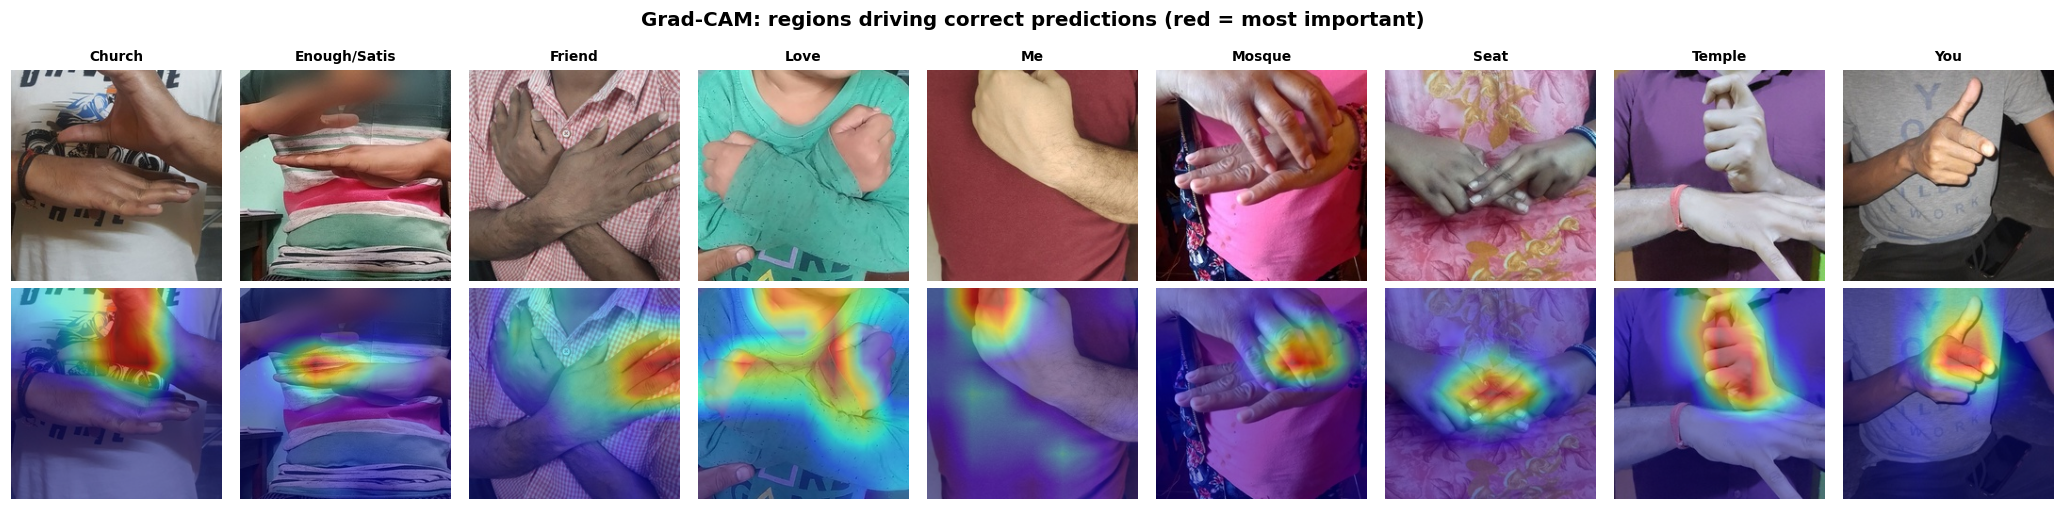

In [12]:
# One correctly classified test image per sign: original and Grad-CAM overlay
rng = np.random.default_rng(ku.SEED)
fig, axes = plt.subplots(2, N, figsize=(2.1 * N, 4.8))
for c in range(N):
    candidates = np.where((y_true == c) & correct)[0]
    if len(candidates) == 0:                      # fallback: any image of this sign
        candidates = np.where(y_true == c)[0]
    i = rng.choice(candidates)
    cam, _ = grad_cam(dl_model, X_test[i])
    axes[0, c].imshow(X_test[i])
    axes[1, c].imshow(overlay(X_test[i], cam))
    axes[0, c].set_title(CLASS_NAMES[c][:12], fontsize=9)
    for r in range(2):
        axes[r, c].axis("off")
fig.suptitle("Grad-CAM: regions driving correct predictions (red = most important)", fontsize=13, fontweight="bold")
fig.tight_layout()
ku.save_figure(fig, "06_gradcam_correct", NOTEBOOK, caption="Grad-CAM heatmaps for one correctly classified image of each sign.")
plt.show()

Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/06_gradcam_mistakes.png


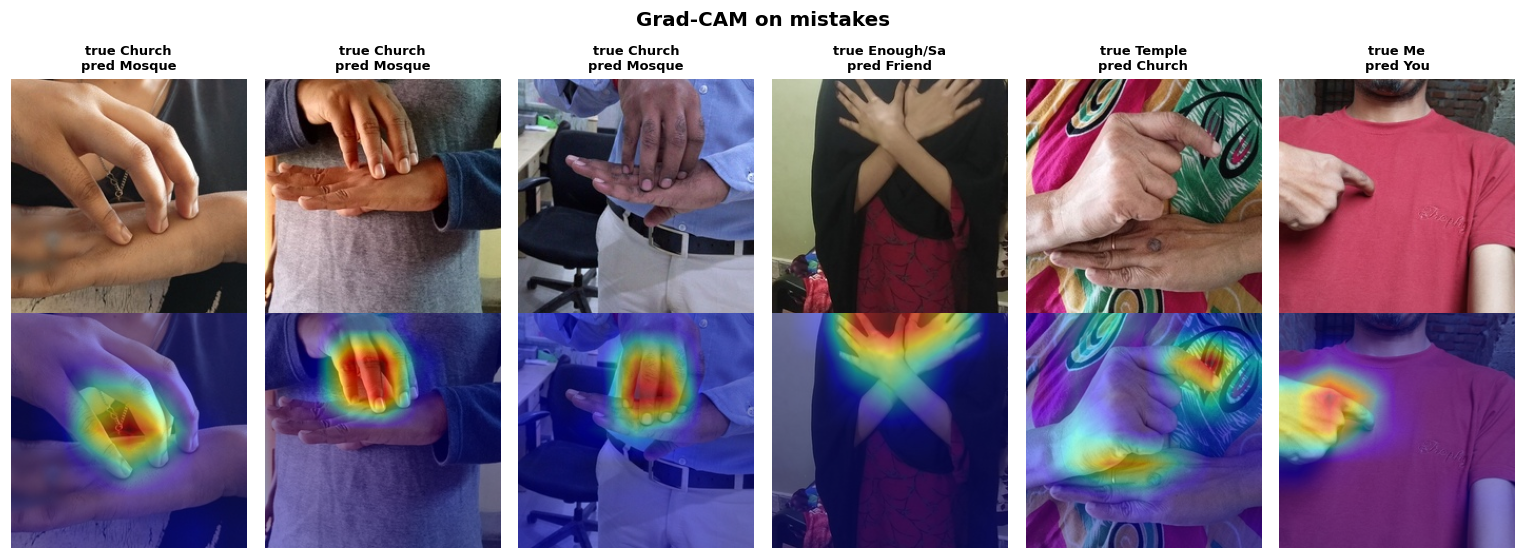

In [13]:
# Grad-CAM for 6 of the most confident mistakes: what misled the model?
fig, axes = plt.subplots(2, 6, figsize=(14, 5.2))
for c, i in enumerate(worst[:6]):
    cam, _ = grad_cam(dl_model, X_test[i])
    axes[0, c].imshow(X_test[i])
    axes[1, c].imshow(overlay(X_test[i], cam))
    axes[0, c].set_title(f"true {CLASS_NAMES[y_true[i]][:9]}\npred {CLASS_NAMES[dl_pred[i]][:9]}", fontsize=8.5)
    for r in range(2):
        axes[r, c].axis("off")
fig.suptitle("Grad-CAM on mistakes", fontsize=13, fontweight="bold")
fig.tight_layout()
ku.save_figure(fig, "06_gradcam_mistakes", NOTEBOOK, caption="Grad-CAM heatmaps for six confident misclassifications.")
plt.show()

**Interpretation:** for correct predictions the heat sits on the **hands and fingers**: the stacked palms for *Church* and *Enough/Satisfied*, the interlocked fingers for *Seat* and *Mosque*, the pointing thumb for *You*, and the peaked fingers for *Temple*. Background, clothing patterns and faces are mostly ignored, so the model has learned the signs themselves, not shortcuts. For crossed-arm signs (*Love*, *Friend*) attention spreads along the arms, and for *Me* it partly falls on the shoulder area, which matches these being the weaker signs.

On the mistakes, the model still **looks at the hands** but reads them as a similar sign (e.g. fingers resting on the other hand → *Mosque*). Its errors come from fine shape ambiguity (or wrong labels), **not from looking in the wrong place**.

## 7 · Robustness to real-world conditions
No photos from new signers were collected, so robustness is tested by **altering the test images** to imitate conditions a real user might create, and measuring how much accuracy each model loses:

| Condition | Levels | Imitates |
|---|---|---|
| Blur | Gaussian radius 2, 4 px | Shaky hands, out-of-focus camera |
| Darkness | brightness × 0.6, × 0.35 | Dim rooms, evening light |
| Rotation | 15°, 30° | Tilted phone |
| Noise | Gaussian σ = 15, 30 | Low-quality camera, low light grain |

The images are altered **after** preprocessing, so both models see the same altered 224×224 picture.

In [14]:
def perturb(images: np.ndarray, kind: str, level: float) -> np.ndarray:
    """Apply one alteration to every image."""
    out = []
    rng = np.random.default_rng(ku.SEED)
    for im in images:
        pil = Image.fromarray(im)
        if kind == "blur":
            pil = pil.filter(ImageFilter.GaussianBlur(level))
        elif kind == "darkness":
            pil = ImageEnhance.Brightness(pil).enhance(level)
        elif kind == "rotation":
            pil = pil.rotate(level, resample=Image.Resampling.BILINEAR, fillcolor=(0, 0, 0))
        arr = np.asarray(pil).astype(np.float32)
        if kind == "noise":
            arr = arr + rng.normal(0, level, arr.shape)
        out.append(np.clip(arr, 0, 255).astype(np.uint8))
    return np.stack(out)

CONDITIONS = [("original", None, None), ("blur", 2, "blur r=2"), ("blur", 4, "blur r=4"),
              ("darkness", 0.6, "dark ×0.6"), ("darkness", 0.35, "dark ×0.35"),
              ("rotation", 15, "rotate 15°"), ("rotation", 30, "rotate 30°"),
              ("noise", 15, "noise σ=15"), ("noise", 30, "noise σ=30")]

rob_rows, examples = [], {}
for kind, level, label in tqdm(CONDITIONS, desc="Robustness tests"):
    imgs = X_test if kind == "original" else perturb(X_test, kind, level)
    label = label or "original"
    examples[label] = imgs[0]
    rob_rows.append({"condition": label,
                     "deep_learning": accuracy_score(y_true, dl_predict(imgs).argmax(axis=1)),
                     "classic": accuracy_score(y_true, classic_predict(imgs))})
robust = pd.DataFrame(rob_rows)
robust["dl_drop_pts"] = 100 * (robust["deep_learning"] - robust.loc[0, "deep_learning"])
robust["classic_drop_pts"] = 100 * (robust["classic"] - robust.loc[0, "classic"])
ku.save_table(robust.round(4), "06_robustness", NOTEBOOK,
              caption="Test accuracy of both models under blur, darkness, rotation and noise.")
ku.log_result("robustness", robust.set_index("condition")[["deep_learning", "classic"]].round(4).to_dict(), NOTEBOOK)
robust.round(3)

Robustness tests:   0%|          | 0/9 [00:00<?, ?it/s]

Table saved  -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/tables/06_robustness.csv
Result logged: robustness = {'deep_learning': {'original': 0.8502, 'blur r=2': 0.8353, 'blur r=4': 0.6738, 'dark ×0.6': 0.8533, 'dark ×0.35': 0.8363, 'rotate 15°': 0.8098, 'rotate 30°': 0.7418, 'noise σ=15': 0.8448, 'noise σ=30': 0.7683}, 'classic': {'original': 0.6004, 'blur r=2': 0.6047, 'blur r=4': 0.5675, 'dark ×0.6': 0.6089, 'dark ×0.35': 0.61, 'rotate 15°': 0.4442, 'rotate 30°': 0.17, 'noise σ=15': 0.6026, 'noise σ=30': 0.5983}}


,condition,deep_learning,classic,dl_drop_pts,classic_drop_pts
0,original,0.850,0.600,0.000,0.000
1,blur r=2,0.835,0.605,-1.488,0.425
2,blur r=4,0.674,0.567,-17.641,-3.294
3,dark ×0.6,0.853,0.609,0.319,0.850
4,dark ×0.35,0.836,0.610,-1.382,0.956
5,rotate 15°,0.810,0.444,-4.038,-15.622
6,rotate 30°,0.742,0.170,-10.840,-43.039
7,noise σ=15,0.845,0.603,-0.531,0.213
8,noise σ=30,0.768,0.598,-8.183,-0.213


Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/06_robustness.png


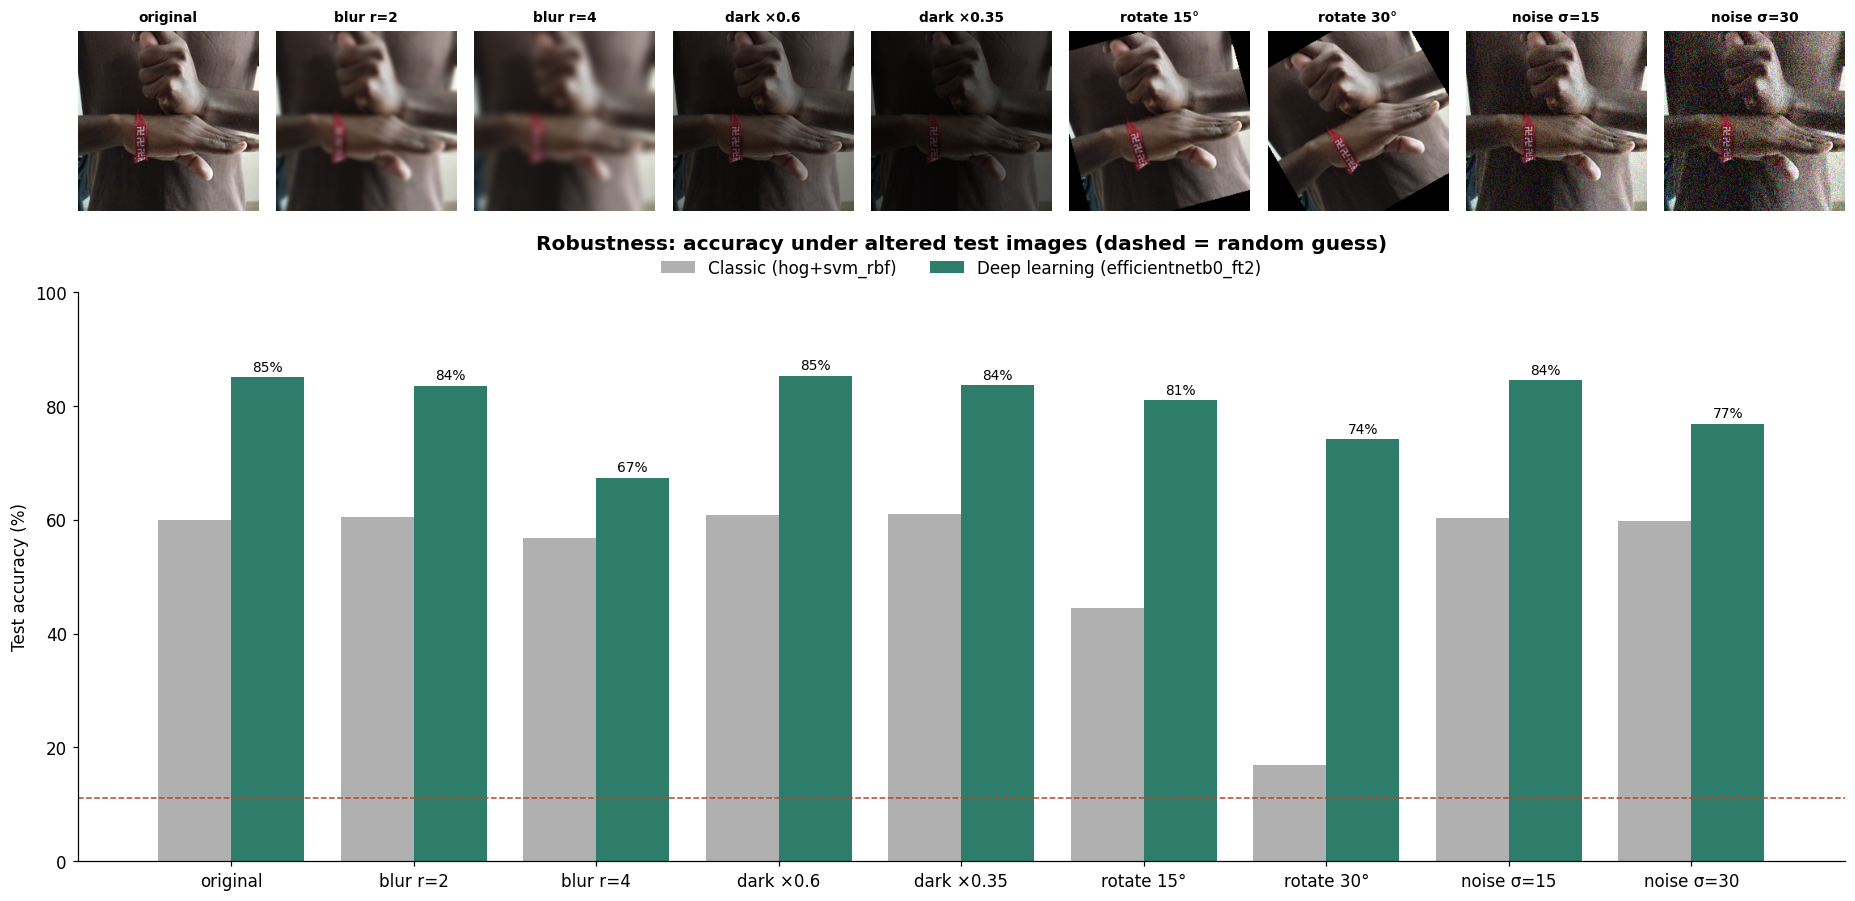

In [15]:
# Example of each alteration (first test image) and the accuracy chart
fig = plt.figure(figsize=(17, 8.5))
gs = fig.add_gridspec(2, len(CONDITIONS), height_ratios=[1, 2.2])
for c, label in enumerate(examples):
    ax = fig.add_subplot(gs[0, c])
    ax.imshow(examples[label])
    ax.set_title(label, fontsize=9)
    ax.axis("off")

ax = fig.add_subplot(gs[1, :])
xx = np.arange(len(robust))
ax.bar(xx - 0.2, robust["classic"] * 100, width=0.4, color=CLASSIC_COLOUR, label=f"Classic ({CLASSIC_NAME})")
b = ax.bar(xx + 0.2, robust["deep_learning"] * 100, width=0.4, color=DL_COLOUR, label=f"Deep learning ({DL_NAME})")
ax.bar_label(b, labels=[f"{v:.0f}%" for v in robust["deep_learning"] * 100], padding=2, fontsize=9)
ax.axhline(100 / N, color="#B5482B", linestyle="--", linewidth=1)
ax.set_xticks(xx, robust["condition"])
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 100)
ax.set_title("Robustness: accuracy under altered test images (dashed = random guess)", pad=28)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
fig.tight_layout()
ku.save_figure(fig, "06_robustness", NOTEBOOK, caption="Accuracy of both models when test images are blurred, darkened, rotated or noisy.")
plt.show()

**Interpretation:**
- **Darkness barely matters** for either model (deep model 85.3% and 83.6%), helped by brightness augmentation during training.
- **Rotation is where deep learning shines:** at 30° the classic model collapses from 60.0% to **17.0%** (near random), while the deep model keeps **74.2%** (−10.8 points), thanks to rotation augmentation and learned shape features.
- **Heavy blur (radius 4) is the deep model's weak spot (−17.6 points to 67.4%)** and strong noise costs 8.2 points. HOG is almost unaffected by these because it already works on a coarse 64×64 greyscale image, so it has less fine detail to lose. The deep model relies on fine finger detail, which blur and noise destroy.
- **Practical implications:** the app should ask users to hold the phone steady in good focus; future work should add stronger blur and noise augmentation and, ideally, photos from new signers.

## Check · Project status

In [16]:
ku.project_summary()

Project root : /content/drive/MyDrive/DSA4050/ksl-recognition
Figures      : 28
Tables       : 18
Models       : 6
Results      : 52
Experiments  : 12


## Findings for the report
- **Headline:** EfficientNetB0 (extended fine-tuning) reaches **85.0% test accuracy (95% CI 82.7–87.2%)**, macro-F1 0.850, against **60.0% (57.1–63.2%)** for HOG + SVM; the confidence intervals do not overlap. Top-2 accuracy is **94.7%**. (Notebook 05 measured 86.0%; the difference comes from JPEG decoding libraries and lies within the CI.)
- **Every sign improves** (+0.15 to +0.31 F1), most for Temple, Enough/Satisfied, Seat and You. The hardest remaining pairs are *Friend ↔ Love* (23.8% / 14.6% confusion) and *Mosque ↔ Church* (≈6%).
- **Confidence is informative:** median 0.99 when correct vs 0.62 when wrong. A **0.80 threshold** answers 78.6% of images with **95.9% accuracy**; the dashboard uses it.
- **Grad-CAM** shows the model attends to the **hands and fingers**, not background or clothing, even when it is wrong.
- **Label noise:** several of the most confident errors appear to be **mislabelled images** (e.g. *Church* labels on images showing the *Mosque* sign), suggesting the true accuracy may be slightly higher; this cannot be verified without expert signers.
- **Robustness:** strong to darkness (≤1.4-point drop) and far more robust to rotation than the classic model (30°: 74.2% vs 17.0%), but sensitive to **heavy blur (−17.6 points)** and strong noise (−8.2 points).
- **Limitations:** 9 isolated signs; signers may appear in both training and test sets (no signer IDs); no photos from new signers; centre crop occasionally cuts hands in landscape photos; labels not verified by Deaf signers.

**Next:** the interactive dashboard (part d).